In [1]:
import os
# from fair import FAIR
# from fair.io import read_properties
# from fair.interface import initialise
# from fair.structure.units import desired_emissions_units
import numpy as np
import pandas as pd


import xarray as xr
from pathlib import Path
import glob
from drawdown import DATA_DIR
from drawdown import kernels
import string
import pandas as pd
import datetime
from utils import zenodo, CEDS
from drawdown import explorer
from drawdown.explorer import stack
from drawdown import brakes

random_seed=123


from scipy.optimize import brentq

import matplotlib.cm as cm
import seaborn as sns
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings('ignore')

In [ ]:
for_talk=True
if for_talk:
    import matplotlib.font_manager as fm
    plt.style.use("dark_background")

    # register the bundled Drawdown fonts (SIL Open Font License, see data/fonts/*/OFL.txt)
    font_files = sorted((DATA_DIR / "fonts").glob("*/*.ttf"))
    for font_file in font_files:
        fm.fontManager.addfont(str(font_file))

    # Bebas Neue as the base font for everything (labels, ticks, legends);
    # matplotlib falls back to its default font if it isn't registered
    if any(font.name == "Bebas Neue" for font in fm.fontManager.ttflist):
        plt.rcParams["font.family"] = "Bebas Neue"
    else:
        print(f"Bebas Neue not found in {DATA_DIR / 'fonts'}; using the default font")
    plt.rcParams.update({'font.size': 14})

    default_figsize=(13.33, 7.5)
else:
    plt.style.use("default")
    default_figsize=(6.4,4.8)

In [3]:
from importlib import reload
reload(explorer)

<module 'drawdown.explorer' from '/Users/katemarvel/Documents/DrawdownImpacts/drawdown/explorer.py'>

In [4]:
lite=True

In [5]:
d={}

# A)  Control Scenario.  

Historic emissions until 2026, and then flat (no change) emissions after 2026. Just to show us what would help if nothhing changes.

In [6]:
baseline_scenario="constant"


# B) Aerosol Unmasking.  
Start with A, but then aerosol unmasking. Accelerated warming.


In [7]:
aerosol_scenario="low"
arr=CEDS._CEDS_species
to_remove=["CH4","CO2","N20"]
CEDS_aerosols= arr[~np.isin(arr, to_remove)]
aerosol_species=[CEDS.CEDS_name_to_FAIR(x) for x in CEDS_aerosols]


low_aerosol_dict={}
for specie in aerosol_species:
    low_aerosol_dict[specie]=aerosol_scenario
highlow_dict={"B":low_aerosol_dict}
for specie in aerosol_species:
    highlow_dict[f"{aerosol_scenario}-{specie}"]={specie:aerosol_scenario}

# dictionary of dictionaries
aerosol_reductions=explorer.scenarios_to_emissions(baseline_scenario,{"B":low_aerosol_dict})
#just the components without the scenario name
aerosols_only=aerosol_reductions["B"]
d["B"]= aerosols_only

# C)  Gradual Emissions Cuts — Net Zero 2100.  
Start with A, but with emissions dropping to zero by 2100.

In [8]:
ghg_scenario="low"



#ghg_species=["N2O","CH4","CO2 FFI", "CO2 AFOLU" ]
ghg_species=["CO2 FFI", "CO2 AFOLU" ]

low_ghg_dict={}
for specie in ghg_species:
    low_ghg_dict[specie]=ghg_scenario
highlow_dict_ghg={"C":low_ghg_dict}
for specie in ghg_species:
    highlow_dict_ghg[f"{ghg_scenario}-{specie}"]={specie:ghg_scenario}

# dictionary of dictionaries
ghg_reductions=explorer.scenarios_to_emissions(baseline_scenario,{"C":low_ghg_dict})
#just the components without the scenario name
ghgs_only=ghg_reductions[f"C"]
d["C"]=ghgs_only

# D) Gradual Emissions Cuts — Net Zero 2100, with Aerosol Unmasking.  
Start with B, but with emissions dropping to zero by 2100.

In [9]:

d["D"]=explorer.stack(ghg_reductions[f"C"],aerosol_reductions[f"B"])

# E) Pulling Emergency Brakes 
Start with C, but pull high achievable emergency brakes for methane, forests, etc.

In [10]:
# years to half adoption for each deployment speed class
fast_time=3
medium_time=7
slow_time=12

In [22]:
SPEED = brakes.make_speeds(fast_time, medium_time, slow_time)
# additional adoption at saturation; brakes.adoption_ceilings("low") for the low achievable range
ADD = brakes.adoption_ceilings("high")


In [23]:
# pull the brakes this year
perts = brakes.build_brakes(2027, speed=SPEED, add=ADD)

### Adding in the land emergency brakes


In [24]:
forest_adoption_speed="fast"
year_implemented = 2027

# all land by default; narrow with e.g. ecosystem="forest", climate_zone=["tropical","boreal"]
forest_dict = brakes.build_land_brakes(year_implemented, adoption_speed=forest_adoption_speed,
                                       speed=SPEED, add=ADD)

# --- combine against the aerosol-unmasking backdrop and the other brakes ---
forest_dict[f"All land protection + {aerosol_scenario}-allaer"] = stack(forest_dict["All land protection"],
                                                                        aerosols_only)

forest_dict["All land protection + All brakes"] = stack(forest_dict["All land protection"],perts["All brakes"])


In [25]:
d["E" ] = explorer.stack(forest_dict['All land protection + All brakes'], ghg_reductions[f"C"])

# F) Pulling Low Emergency Brakes 
Start with C, but pull low achievable emergency brakes for methane, forests, etc.

In [28]:
# low brake scenario
lowbrakes = brakes.build_brakes(2027, speed=SPEED, add=brakes.adoption_ceilings("low"))
lowland = brakes.build_land_brakes(2027, speed=SPEED, add=brakes.adoption_ceilings("low"))
d["F" ] = explorer.stack(lowland['All land protection'], 
                         lowbrakes["All brakes"],
                         ghg_reductions[f"C"])

# G) Pulling Global Methane Pledge-aligned emergency brakes

In [38]:
# G) E's brakes, plus the Global Methane Pledge and continued CH4 reductions:
#   1. rapid cut: CH4 never above a path falling to 30% below 2020 by 2030, then
#      straight down to the "low" scenario's 2100 value
#   2. continual reduction: once E's brakes saturate (E declines more slowly than
#      the straight line to low-2100 would), switch to that straight line
gmp_start = 2027
gmp_2030_fraction = 0.7     # 2030 CH4 as a fraction of 2020 (0.7 = 30% cut)

# absolute CH4 paths for the baseline and for "low" (no model run, just emissions)
fe = explorer.replacement_model(baseline_scenario, {"low CH4": {"CH4": "low"}},
                                lite=True, n_lite=1, run_model=False)
ch4 = fe.emissions.sel(specie="CH4").isel(config=0)
ch4_base = ch4.sel(scenario=baseline_scenario).values
ch4_low = ch4.sel(scenario="low CH4").values
timepoints = np.arange(1750, 2102)
at = lambda arr, year: arr[timepoints == year][0]
low_2100 = at(ch4_low, 2100)

ch4_E = ch4_base + d["E"]["CH4"]

# 1. GMP ceiling: baseline until gmp_start, 2030 target, then straight to low-2100
ceiling = np.interp(timepoints,
                    [gmp_start - 1, 2030, 2100],
                    [at(ch4_base, gmp_start - 1), gmp_2030_fraction * at(ch4_base, 2020), low_2100])
ceiling = np.where(timepoints < gmp_start, ch4_base, ceiling)
ch4_G = np.minimum(ch4_E, ceiling)

# 2. switch year: E is below the ceiling and now declining more slowly than a
#    straight line from E to low-2100 would
decline = -np.diff(ch4_E, append=ch4_E[-1])
needed = (ch4_E - low_2100) / np.maximum(2100 - timepoints, 1)
switch = (timepoints >= 2030) & (timepoints < 2100) & (ch4_E < ceiling) & (decline < needed)
if switch.any():
    t_switch = timepoints[switch][0]
    line = np.interp(timepoints, [t_switch, 2100], [at(ch4_E, t_switch), low_2100])
    ch4_G = np.where(timepoints > t_switch, line, ch4_G)
    

# copy E (don't alias it) and swap in the new CH4 perturbation
d["G"] = dict(d["E"])
d["G"]["CH4"] = ch4_G - ch4_base



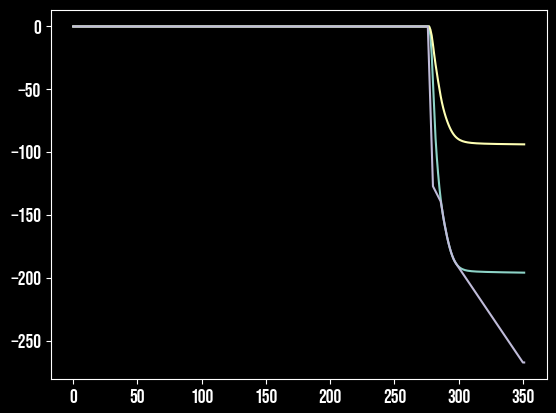

In [39]:
plt.plot(d["E"]["CH4"])
plt.plot(d["F"]["CH4"])
plt.plot(d["G"]["CH4"])

In [34]:
f= explorer.drawdown_model("constant",d,lite=lite, emissions_year=2024)

Running 70 projections in parallel:   0%|          | 0/352 [00:00<?, ?timesteps/s]

In [45]:
reload(explorer)

<module 'drawdown.explorer' from '/Users/katemarvel/Documents/DrawdownImpacts/drawdown/explorer.py'>

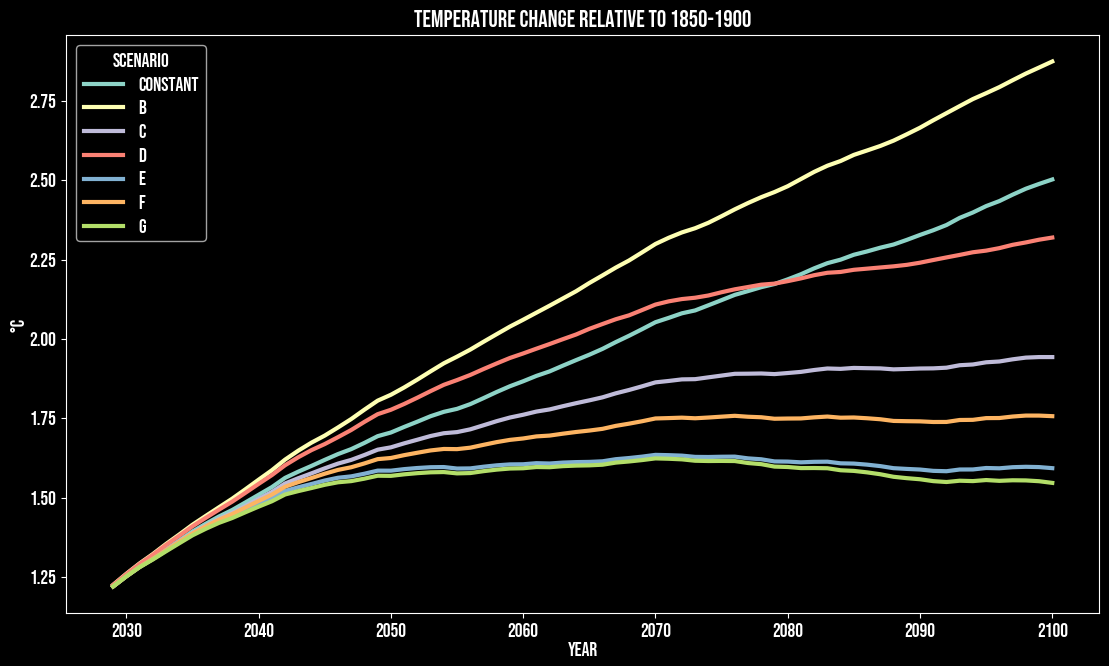

In [46]:
plt.figure(figsize=default_figsize)
explorer.plot_temp(f,running_mean=20,timebounds=(2010,2100),lw=3)

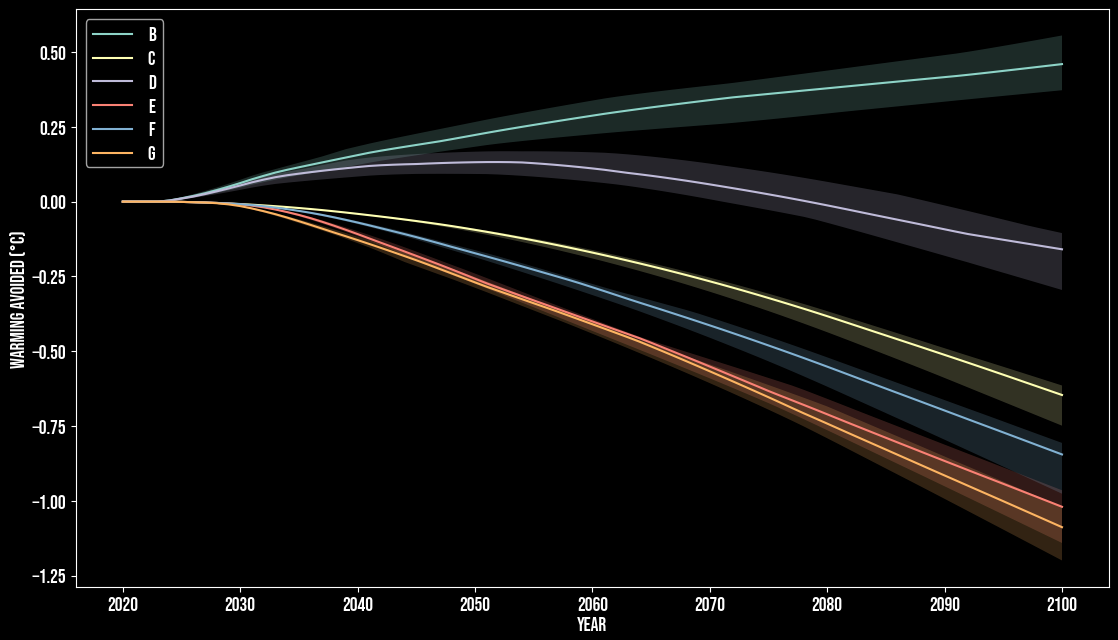

In [40]:
plt.figure(figsize=default_figsize)
explorer.plot_T_diff(f)

In [44]:
os.makedirs("../plots", exist_ok=True)
f.temperature.sel(layer=0).median(dim="config").to_pandas().to_csv("../plots/scenarios.csv")